In [ ]:
import os
import tarfile
import glob
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# CONFIGURACIÓN DE RUTAS Y FORMATOS
# ==========================================
BASE_FOLDERNAME = "Poisson_2_1_conMDlogs_ALL"
RESULTS_DIR = f"./results/{BASE_FOLDERNAME}"

SUFFIX_STREAM_0 = "1_1"  # Stream Crítico / Prioritario
SUFFIX_STREAM_1 = "1_2"  # Stream No Crítico

schedulers_to_plot = ["MLWDF_W1_Q0", "MLWDF_W1_Q1", "MLWDF_W0_Q1"]
per_values = [0, 2, 4, 6, 8, 10]

# ------------------------------------------
# PARÁMETROS EXPERIMENTALES SELECCIONABLES
# ------------------------------------------
TARGET_SAT = 90       # <-- CAMBIA AQUÍ: Elige la saturación a graficar (50, 70 o 90)
NUM_RUNS_TO_USE = 5  # <-- CAMBIA AQUÍ: Elige cuántas iteraciones usar por caso

def fast_parse_and_calculate_delay(cli_bytes, srv_bytes):
    """
    Extrae secuencialmente los timestamps sin mapear por ID,
    ajusta las longitudes al mínimo común y calcula el retraso.
    """
    if not cli_bytes or not srv_bytes:
        return np.nan
    
    # Extraer marcas de tiempo de transmisión (Cliente)
    tx_times = []
    for line in cli_bytes.decode('utf-8', errors='ignore').splitlines():
        parts = line.split()
        if parts:
            try:
                tx_times.append(float(parts[0]))
            except ValueError:
                continue

    # Extraer marcas de tiempo de recepción (Servidor)
    rx_times = []
    for line in srv_bytes.decode('utf-8', errors='ignore').splitlines():
        parts = line.split()
        if parts:
            try:
                rx_times.append(float(parts[0]))
            except ValueError:
                continue

    # Si alguno de los dos archivos quedó completamente vacío
    if not tx_times or not rx_times:
        return np.nan

    # Determinar la longitud mínima para corregir cualquier descuadre de líneas
    if len(tx_times) != len(rx_times):
        print(f"    [WARNING] Desajuste de líneas: Cliente={len(tx_times)} vs Servidor={len(rx_times)}. Se recortará al mínimo común.")
    min_len = min(len(tx_times), len(rx_times))
    
    # Convertir a vectores de NumPy recortados al tamaño común
    tx_vector = np.array(tx_times[:min_len])
    rx_vector = np.array(rx_times[:min_len])
    
    # Resta vectorial directa
    delays = rx_vector - tx_vector
    
    # Filtrar posibles valores negativos (por ejemplo, retransmisiones extrañas o corrupción)
    valid_delays = delays[delays >= 0]
    
    return np.mean(valid_delays) if valid_delays.size > 0 else np.nan

def process_tarfile_raw_runs(tar_path, max_runs):
    buffer_matrix = {}
    ignored_runs = 0
    
    with tarfile.open(tar_path, "r:gz") as tar:
        for m in tar.getmembers():
            if not m.isfile(): continue
            match_folder = re.search(r"SAT\d+/(DELAY\d+_PER\d+/RUN\d+)", m.name)
            if not match_folder: continue
            
            sim_key = match_folder.group(1)
            
            # Filtrar run_id dinámicamente
            meta_match = re.search(r"RUN(\d+)", sim_key)
            if meta_match and int(meta_match.group(1)) >= max_runs:
                ignored_runs += 1
                continue
                
            if sim_key not in buffer_matrix:
                buffer_matrix[sim_key] = {'c0': None, 's0': None, 'c1': None, 's1': None}
            
            filename = m.name
            if "go_client" in filename:
                if f"logClient_{SUFFIX_STREAM_0}.log" in filename: buffer_matrix[sim_key]['c0'] = tar.extractfile(m).read()
                elif f"logClient_{SUFFIX_STREAM_1}.log" in filename: buffer_matrix[sim_key]['c1'] = tar.extractfile(m).read()
            elif "go_server" in filename:
                if f"logServer_{SUFFIX_STREAM_0}.log" in filename: buffer_matrix[sim_key]['s0'] = tar.extractfile(m).read()
                elif f"logServer_{SUFFIX_STREAM_1}.log" in filename: buffer_matrix[sim_key]['s1'] = tar.extractfile(m).read()

    if ignored_runs > 0:
        print(f"    [INFO] Se omitieron {int(ignored_runs/4)} subcarpetas RUN por superar el límite estipulado.")

    print(f"    [PARSING] Procesando {len(buffer_matrix)} ejecuciones válidas encontradas en memoria RAM...")
    
    records = []
    for sim_key, bufs in buffer_matrix.items():
        meta_match = re.search(r"DELAY(\d+)_PER(\d+)/RUN(\d+)", sim_key)
        delay_val, per_val, run_id = map(int, meta_match.groups())
        
        d0 = fast_parse_and_calculate_delay(bufs['c0'], bufs['s0'])
        d1 = fast_parse_and_calculate_delay(bufs['c1'], bufs['s1'])
        # print(f"    [DEBUG] RUN {run_id}: PER {per_val}% | D0={d0*1e-3:.4f} | D1={d1*1e-3:.4f}")
        # CAMBIO CLAVE: Cambiada la validación y el cálculo para dividir d0 / d1 en lugar de d1 / d0
        # if not np.isnan(d0) and not np.isnan(d1) and d1 > 0:
        #     records.append((per_val, d0 / d1))
            
    # return records

# ==========================================
# PROCESAMIENTO MATRICIAL CON FILTRADO Y LOGS
# ==========================================
aggregated_ratios = {}

tar_pattern = os.path.join(RESULTS_DIR, "**", f"SAT{TARGET_SAT}.tar.gz")
all_compressed_packages = glob.glob(tar_pattern, recursive=True)
total_packages = len(all_compressed_packages)

print("="*80)
print(f"  INICIANDO PROCESAMIENTO FILTRADO POR SATURACIÓN")
print(f"  Saturación elegida: {TARGET_SAT}%")
print(f"  Límite: Máximo {NUM_RUNS_TO_USE} RUNs por caso")
print(f"  Paquetes detectados que coinciden: {total_packages}")
print("="*80)

for idx, tar_path in enumerate(all_compressed_packages, start=1):
    normalized_path = tar_path.replace("\\", "/")
    
    if "MLWDF" in normalized_path:
        match_mlwdf = re.search(r"MLWDF/([^/]+)/GAMMA_CRIT_([\d\.]+)/", normalized_path)
        if not match_mlwdf: continue
        sched_label = f"MLWDF_{match_mlwdf.group(1)}"
        gamma_crit = float(match_mlwdf.group(2))
    else:
        match_basic = re.search(r"([^/]+)/SAT\d+\.tar\.gz$", normalized_path)
        if not match_basic: continue
        sched_label = match_basic.group(1)
        gamma_crit = 1.0

    if sched_label not in schedulers_to_plot:
        continue

    print(f"\n[{idx}/{total_packages}] -> ABRIENDO: {os.path.basename(tar_path)}")
    print(f"    Mapeado como: Scheduler={sched_label} | Saturation={TARGET_SAT}% | Gamma={gamma_crit}")

    extracted_items = process_tarfile_raw_runs(tar_path, max_runs=NUM_RUNS_TO_USE)
    
    for per_val, ratio in extracted_items:
        key = (sched_label, TARGET_SAT, gamma_crit, per_val)
        aggregated_ratios.setdefault(key, []).append(ratio)

print("\n" + "="*80)
print("  [PROCESAMIENTO COMPLETO] Reduciendo colecciones numéricas a medias...")
print("="*80)

final_data = {k: np.mean(v) for k, v in aggregated_ratios.items() if v}

# ==========================================
# COMPONENTE GRÁFICO Y EXPORTACIÓN
# ==========================================
if final_data:
    unique_scheds = sorted(list(set(k[0] for k in final_data.keys())))
    
    for current_sched in unique_scheds:
        print(f"\n[PLOT] Renderizando curvas por PER para: {current_sched} en SAT {TARGET_SAT}%")
        
        fig, ax = plt.subplots(figsize=(8, 5.2), dpi=120)
        fig.suptitle(f"Metrics (SAT {TARGET_SAT}% - {NUM_RUNS_TO_USE} Runs) - {current_sched}", fontsize=13, fontweight='bold', y=0.98)
        
        colors_palette = ["#1f77b4", "#aec7e8", "#ff7f0e", "#ffbb78", "#2ca02c", "#d62728"]
        legend_handles = []

        gammas = sorted(list(set(k[2] for k in final_data.keys() if k[0] == current_sched and k[1] == TARGET_SAT)))
        tikz_export_data = []

        for per_idx, current_per in enumerate(per_values):
            ratios_per_gamma = []
            
            for g in gammas:
                val = final_data.get((current_sched, TARGET_SAT, g, current_per), np.nan)
                ratios_per_gamma.append(val)
                if not np.isnan(val):
                    tikz_export_data.append({
                        'Saturation': TARGET_SAT, 'PER': current_per, 'Gamma': g, 'Ratio_Mean': val
                    })
            
            line, = ax.plot(gammas, ratios_per_gamma, color=colors_palette[per_idx], 
                            linewidth=1.8, marker='o', markersize=5, label=f"PER {current_per}%")
            legend_handles.append(line)
        
        ax.set_xlabel(r"$\gamma_{\mathrm{crit}}$", fontsize=12)
        # CAMBIO VISUAL: Se actualizó el formato matemático del eje Y para que muestre D_crit / D_non-crit
        ax.set_ylabel(r"$\mathbb{E}[D_{\mathrm{non-crit}}] / \mathbb{E}[D_{\mathrm{crit}}]$", fontsize=12)
        ax.set_xticks(gammas)
        ax.axhline(1.0, color='gray', linestyle='--', linewidth=0.8, alpha=0.7)
        ax.grid(True, linestyle=":", alpha=0.6)
        
        if tikz_export_data:
            csv_name = f"{current_sched}_SAT{TARGET_SAT}_ratios_inverse_tikz.csv"
            pd.DataFrame(tikz_export_data).to_csv(csv_name, index=False)
            print(f"    [EXPORT] Guardado dataset para TikZ en: {csv_name}")

        ax.legend(loc='upper left', frameon=True, fontsize=10)
        plt.tight_layout()
        plt.show()
else:
    print(f"❌ Error: No se encontraron datos para procesar en la saturación de {TARGET_SAT}%.")

  INICIANDO PROCESAMIENTO FILTRADO POR SATURACIÓN
  Saturación elegida: 90%
  Límite: Máximo 5 RUNs por caso
  Paquetes detectados que coinciden: 20

[3/20] -> ABRIENDO: SAT90.tar.gz
    Mapeado como: Scheduler=MLWDF_W1_Q0 | Saturation=90% | Gamma=8.0
    [PARSING] Procesando 30 ejecuciones válidas encontradas en memoria RAM...
    [WARNING] Desajuste de líneas: Cliente=240571 vs Servidor=240570. Se recortará al mínimo común.
    [WARNING] Desajuste de líneas: Cliente=240571 vs Servidor=240570. Se recortará al mínimo común.
    [WARNING] Desajuste de líneas: Cliente=240571 vs Servidor=240570. Se recortará al mínimo común.
    [WARNING] Desajuste de líneas: Cliente=240571 vs Servidor=240570. Se recortará al mínimo común.
    [WARNING] Desajuste de líneas: Cliente=240571 vs Servidor=240570. Se recortará al mínimo común.

[4/20] -> ABRIENDO: SAT90.tar.gz
    Mapeado como: Scheduler=MLWDF_W1_Q0 | Saturation=90% | Gamma=10.0
    [PARSING] Procesando 30 ejecuciones válidas encontradas en mem

[EXTRACTING] RR | Gamma: 1.0
[EXTRACTING] STBP | Gamma: 1.0
[EXTRACTING] MLWDF_W1_Q0 | Gamma: 8.0
[EXTRACTING] MLWDF_W1_Q0 | Gamma: 10.0
[EXTRACTING] MLWDF_W1_Q0 | Gamma: 1.0
[EXTRACTING] MLWDF_W1_Q0 | Gamma: 4.0
[EXTRACTING] MLWDF_W1_Q0 | Gamma: 2.0
[EXTRACTING] MLWDF_W1_Q0 | Gamma: 6.0
[EXTRACTING] MLWDF_W0_Q1 | Gamma: 8.0
[EXTRACTING] MLWDF_W0_Q1 | Gamma: 10.0
[EXTRACTING] MLWDF_W0_Q1 | Gamma: 1.0
[EXTRACTING] MLWDF_W0_Q1 | Gamma: 4.0
[EXTRACTING] MLWDF_W0_Q1 | Gamma: 2.0
[EXTRACTING] MLWDF_W0_Q1 | Gamma: 6.0
[EXTRACTING] MLWDF_W1_Q1 | Gamma: 8.0
[EXTRACTING] MLWDF_W1_Q1 | Gamma: 10.0
[EXTRACTING] MLWDF_W1_Q1 | Gamma: 1.0
[EXTRACTING] MLWDF_W1_Q1 | Gamma: 4.0
[EXTRACTING] MLWDF_W1_Q1 | Gamma: 2.0
[EXTRACTING] MLWDF_W1_Q1 | Gamma: 6.0


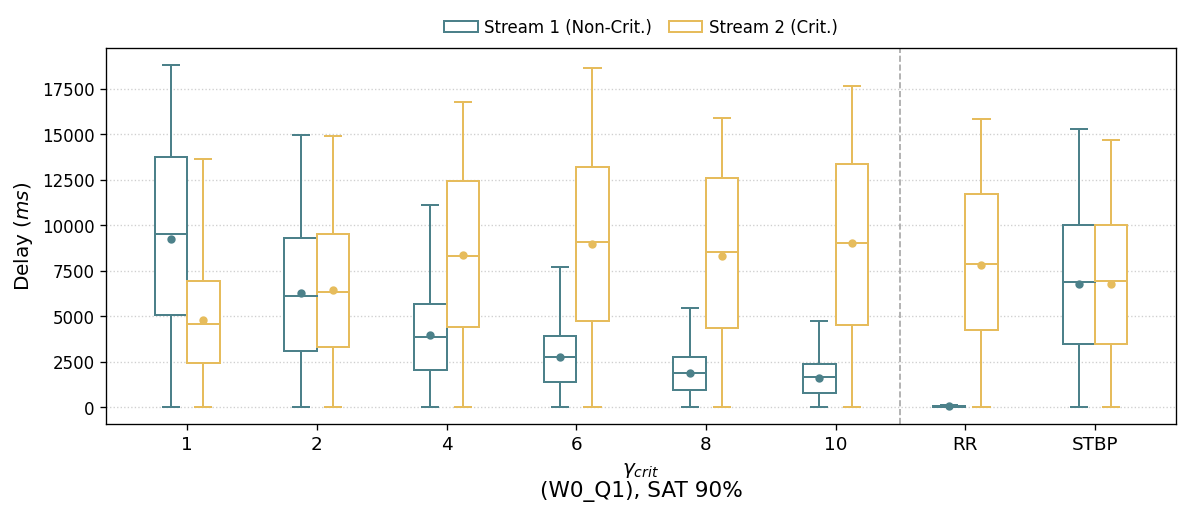

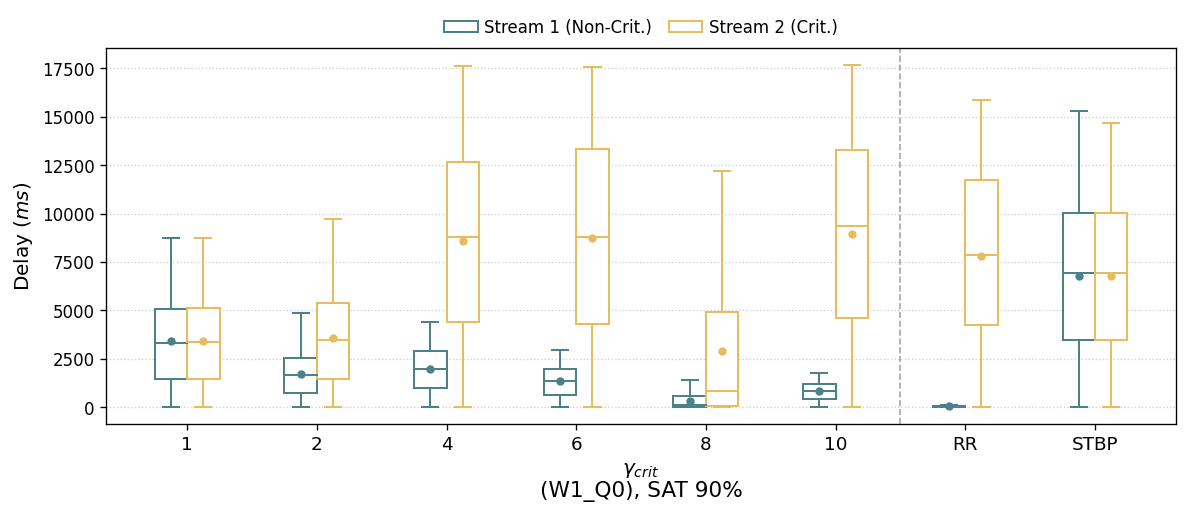

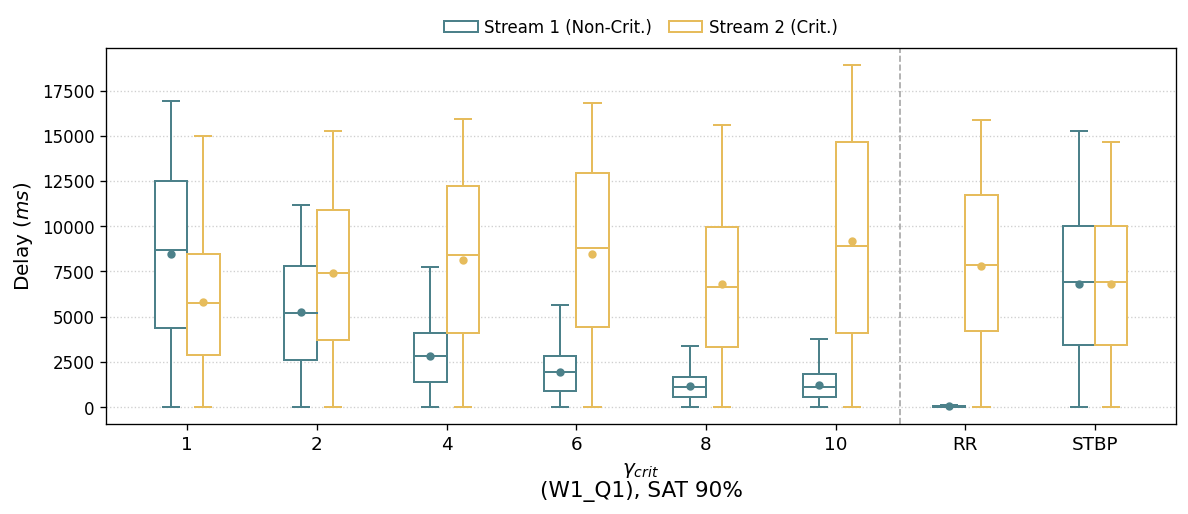

In [1]:
import os
import tarfile
import glob
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# CONFIGURACIÓN DE RUTAS Y FORMATOS
# ==========================================
BASE_FOLDERNAME = "Poisson_2_1_conMDlogs_ALL"
RESULTS_DIR = f"./results/{BASE_FOLDERNAME}"

SUFFIX_STREAM_0 = "1_1"  # Stream Crítico / Prioritario (Stream 2 en tu imagen)
SUFFIX_STREAM_1 = "1_2"  # Stream No Crítico (Stream 1 en tu imagen)

# Queremos procesar todos los schedulers para poder pintar RR y STBP al final
schedulers_to_plot = ["MLWDF_W1_Q0", "MLWDF_W1_Q1", "MLWDF_W0_Q1", "RR", "STBP"]

TARGET_SAT = 90       # <-- Ajustado a 50% como en tu imagen de ejemplo
NUM_RUNS_TO_USE = 5   # <-- Usamos todos los RUNs para ver las distribuciones

def fast_parse_and_calculate_delay(cli_bytes, srv_bytes):
    """Extrae secuencialmente los timestamps y calcula los delays individuales."""
    if not cli_bytes or not srv_bytes: return []
    
    tx_times = []
    for line in cli_bytes.decode('utf-8', errors='ignore').splitlines():
        parts = line.split()
        if parts:
            try: tx_times.append(float(parts[0]))
            except ValueError: continue

    rx_times = []
    for line in srv_bytes.decode('utf-8', errors='ignore').splitlines():
        parts = line.split()
        if parts:
            try: rx_times.append(float(parts[0]))
            except ValueError: continue

    if not tx_times or not rx_times: return []

    min_len = min(len(tx_times), len(rx_times))
    tx_vector = np.array(tx_times[:min_len])
    rx_vector = np.array(rx_times[:min_len])
    
    delays = rx_vector - tx_vector
    valid_delays = delays[delays >= 0]
    
    # OJO: Si tus logs están en segundos, multiplicamos por 1000 para pasar a milisegundos (ms)
    return (valid_delays * 1e-3).tolist() 

def process_tarfile_raw_runs(tar_path, max_runs):
    """Procesa el paquete comprimido extrayendo todos los delays brutos por stream."""
    buffer_matrix = {}
    folder_regex = re.compile(r"SAT\d+/(DELAY\d+_PER8+/RUN\d+)")
    run_regex = re.compile(r"RUN(\d+)")
    
    with tarfile.open(tar_path, "r:gz") as tar:
        for m in tar.getmembers():
            if not m.isfile(): continue
            match_folder = folder_regex.search(m.name)
            if not match_folder: continue
            
            sim_key = match_folder.group(1)
            meta_match = run_regex.search(sim_key)
            if meta_match and int(meta_match.group(1)) >= max_runs: continue
                
            if sim_key not in buffer_matrix:
                buffer_matrix[sim_key] = {'c0': None, 's0': None, 'c1': None, 's1': None}
            
            filename = m.name
            if "go_client" in filename:
                if f"logClient_{SUFFIX_STREAM_0}.log" in filename: buffer_matrix[sim_key]['c0'] = tar.extractfile(m).read()
                elif f"logClient_{SUFFIX_STREAM_1}.log" in filename: buffer_matrix[sim_key]['c1'] = tar.extractfile(m).read()
            elif "go_server" in filename:
                if f"logServer_{SUFFIX_STREAM_0}.log" in filename: buffer_matrix[sim_key]['s0'] = tar.extractfile(m).read()
                elif f"logServer_{SUFFIX_STREAM_1}.log" in filename: buffer_matrix[sim_key]['s1'] = tar.extractfile(m).read()

    delays_stream0 = []
    delays_stream1 = []
    
    for sim_key, bufs in buffer_matrix.items():
        d0 = fast_parse_and_calculate_delay(bufs['c0'], bufs['s0'])
        d1 = fast_parse_and_calculate_delay(bufs['c1'], bufs['s1'])
        delays_stream0.extend(d0)
        delays_stream1.extend(d1)
            
    return delays_stream0, delays_stream1

# ==========================================
# EXTRACCIÓN MÁS AMBICIOSA DE DATOS
# ==========================================
raw_data_storage = {} # Estructura: {(sched, gamma): (all_d0, all_d1)}

tar_pattern = os.path.join(RESULTS_DIR, "**", f"SAT{TARGET_SAT}.tar.gz")
all_compressed_packages = glob.glob(tar_pattern, recursive=True)

for tar_path in all_compressed_packages:
    normalized_path = tar_path.replace("\\", "/")
    
    if "MLWDF" in normalized_path:
        match_mlwdf = re.search(r"MLWDF/([^/]+)/GAMMA_CRIT_([\d\.]+)/", normalized_path)
        if not match_mlwdf: continue
        sched_label = f"MLWDF_{match_mlwdf.group(1)}"
        gamma_crit = float(match_mlwdf.group(2))
    else:
        match_basic = re.search(r"([^/]+)/SAT\d+\.tar\.gz$", normalized_path)
        if not match_basic: continue
        sched_label = match_basic.group(1)
        gamma_crit = 1.0 # Para RR y STBP asignamos 1.0 por defecto temporalmente

    if sched_label not in schedulers_to_plot: continue

    print(f"[EXTRACTING] {sched_label} | Gamma: {gamma_crit}")
    d0_list, d1_list = process_tarfile_raw_runs(tar_path, max_runs=NUM_RUNS_TO_USE)
    
    key = (sched_label, gamma_crit)
    if key not in raw_data_storage:
        raw_data_storage[key] = ([], [])
    raw_data_storage[key][0].extend(d0_list)
    raw_data_storage[key][1].extend(d1_list)

# ==========================================
# RENDERIZADO DE BOXPLOTS ESTILO PAPER
# ==========================================
# Vamos a generar una gráfica por cada variante de MLWDF encontrada (e.g., W1_Q0, W1_Q1)
mlwdf_variants = sorted(list(set(k[0] for k in raw_data_storage.keys() if "MLWDF" in k[0])))

for current_mlwdf in mlwdf_variants:
    # Extraer y ordenar las gammas disponibles para este MLWDF
    available_gammas = sorted([k[1] for k in raw_data_storage.keys() if k[0] == current_mlwdf])
    
    if not available_gammas: continue
    
    fig, ax = plt.subplots(figsize=(10, 4.5), dpi=120)
    
    # Configuración de posiciones en el Eje X para el agrupamiento doble (Side-by-Side)
    # Dejamos espacio al final para RR y STBP
    total_configurations = len(available_gammas) + 2 # Gammas + RR + STBP
    x_positions = np.arange(total_configurations)
    
    width = 0.25 # Ancho de las cajas
    
    # Listas para almacenar los datos finales que irán al boxplot
    data_non_crit = []
    data_crit = []
    x_labels = []
    
    # 1. Añadir los datos del MLWDF actual recorriendo sus gammas
    for g in available_gammas:
        d0, d1 = raw_data_storage.get((current_mlwdf, g), ([], []))
        data_crit.append(d0 if d0 else [0])
        data_non_crit.append(d1 if d1 else [0])
        # Formatear la etiqueta del eje X (si es entero, quitar el .0)
        x_labels.append(str(int(g)) if g.is_integer() else str(g))
        
    # 2. Añadir de forma fija las referencias de RR y STBP al final si existen
    for ref_sched in ["RR", "STBP"]:
        d0, d1 = raw_data_storage.get((ref_sched, 1.0), ([], []))
        data_crit.append(d0 if d0 else [0])
        data_non_crit.append(d1 if d1 else [0])
        x_labels.append(ref_sched)

    # Definición de colores idénticos a tu referencia de TikZ/Matplotlib
    color_non_crit = "#4c818a" # Azul verdoso opaco
    color_crit = "#e6bc5c"     # Dorado/Amarillo ocre
    
    # Dibujar Boxplots del Stream 1 (Non-Critical) desplazas a la izquierda
    bp1 = ax.boxplot(data_non_crit, positions=x_positions - width/2, widths=width,
                     patch_artist=True, showmeans=True, showfliers=False,
                     boxprops=dict(facecolor='white', color=color_non_crit, linewidth=1.2),
                     capprops=dict(color=color_non_crit, linewidth=1.2),
                     whiskerprops=dict(color=color_non_crit, linewidth=1.2),
                     medianprops=dict(color=color_non_crit, linewidth=1.2),
                     meanprops=dict(marker='o', markerfacecolor=color_non_crit, markeredgecolor=color_non_crit, markersize=4))

    # Dibujar Boxplots del Stream 2 (Critical) desplazadas a la derecha
    bp2 = ax.boxplot(data_crit, positions=x_positions + width/2, widths=width,
                     patch_artist=True, showmeans=True, showfliers=False,
                     boxprops=dict(facecolor='white', color=color_crit, linewidth=1.2),
                     capprops=dict(color=color_crit, linewidth=1.2),
                     whiskerprops=dict(color=color_crit, linewidth=1.2),
                     medianprops=dict(color=color_crit, linewidth=1.2),
                     meanprops=dict(marker='o', markerfacecolor=color_crit, markeredgecolor=color_crit, markersize=4))

    # Estética del Eje X y Y
    ax.set_xticks(x_positions)
    ax.set_xticklabels(x_labels, fontsize=11)
    ax.set_xlabel(r"$\gamma_{crit}$", fontsize=12)
    ax.set_ylabel("Delay ($ms$)", fontsize=12)
    
    # Línea divisoria vertical punteada antes de las referencias estáticas (RR y STBP)
    # Se posiciona justo en medio del último valor de gamma y el primer scheduler estático
    divider_x = len(available_gammas) - 0.5
    ax.axvline(x=divider_x, color='gray', linestyle='--', linewidth=1.0, alpha=0.7)
    
    # Rejilla de fondo horizontal clara
    ax.grid(axis='y', linestyle=':', alpha=0.6)
    
    # Título limpio en la parte inferior o superior (Estilo subfigura (a) (b))
    label_clean = current_mlwdf.replace("MLWDF_", "")
    ax.set_title(f"({label_clean}), SAT {TARGET_SAT}%", fontsize=13, y=-0.22, fontweight='normal')

    # Leyenda superior idéntica a la imagen
    ax.legend([bp1["boxes"][0], bp2["boxes"][0]], 
              ['Stream 1 (Non-Crit.)', 'Stream 2 (Crit.)'], 
              loc='upper center', bbox_to_anchor=(0.5, 1.12),
              ncol=2, frameon=False, fontsize=10, handletextpad=0.4, columnspacing=1.0)

    plt.tight_layout()
    plt.show()